In [10]:
import sys
from pathlib import Path


RAIZ = Path.cwd().parent if Path.cwd().name == "notebook_analise" else Path.cwd()
sys.path.append(str(RAIZ))


import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning

from model.mlp import avaliar_configuracao, avaliar_no_teste
from algoritmos.algoritmo_genetico import algoritmo_genetico
from algoritmos.busca import busca_aleatoria
from utils import graficos

warnings.filterwarnings("ignore", category=ConvergenceWarning)


In [11]:
NUM_RUNS = 1

In [12]:
res_busca, res_ga = [], []

for seed in range(NUM_RUNS):
    res_busca.append(busca_aleatoria(avaliar_configuracao, seed=seed))
    res_ga.append(algoritmo_genetico(avaliar_configuracao, seed=seed))
    print(f"Rodada {seed + 1:2d}/{NUM_RUNS} | "
          f"busca={res_busca[-1]['melhor_fitness']:.2%} | "
          f"GA={res_ga[-1]['melhor_fitness']:.2%}")

Rodada  1/1 | busca=96.67% | GA=93.33%


In [13]:
fit_busca = [r["melhor_fitness"] for r in res_busca]
fit_ga = [r["melhor_fitness"] for r in res_ga]

teste_busca = [avaliar_no_teste(r["melhor_params"])["acuracia_teste"] for r in res_busca]
teste_ga = [avaliar_no_teste(r["melhor_params"])["acuracia_teste"] for r in res_ga]

def resumo(nome, fits, testes):
    f, t = np.array(fits) * 100, np.array(testes) * 100
    print(f"{nome:20s} validação: média {f.mean():.2f}% | desvio {f.std():.2f} "
          f"| min {f.min():.2f}% | max {f.max():.2f}%")
    print(f"{'':20s} teste:     média {t.mean():.2f}% | desvio {t.std():.2f}")

resumo("Busca Aleatória", fit_busca, teste_busca)
resumo("Algoritmo Genético", fit_ga, teste_ga)

Busca Aleatória      validação: média 96.67% | desvio 0.00 | min 96.67% | max 96.67%
                     teste:     média 96.67% | desvio 0.00
Algoritmo Genético   validação: média 93.33% | desvio 0.00 | min 93.33% | max 93.33%
                     teste:     média 100.00% | desvio 0.00


In [14]:
i_b = int(np.argmax(fit_busca))
i_g = int(np.argmax(fit_ga))

for nome, i, res in [("Busca Aleatória", i_b, res_busca),
                     ("Algoritmo Genético", i_g, res_ga)]:
    t = avaliar_no_teste(res[i]["melhor_params"])
    print(f"[{nome}] rodada (seed) {i}: {res[i]['melhor_params']}")
    print(f"   validação: {res[i]['melhor_fitness']:.2%} | teste: {t['acuracia_teste']:.2%}")
    print(f"   matriz de confusão: {t['matriz_confusao']}")

[Busca Aleatória] rodada (seed) 0: {'neuronios': 5, 'taxa_aprendizado': 0.001}
   validação: 96.67% | teste: 96.67%
   matriz de confusão: [[10, 0, 0], [0, 9, 1], [0, 0, 10]]
[Algoritmo Genético] rodada (seed) 0: {'neuronios': 5, 'taxa_aprendizado': 0.05}
   validação: 93.33% | teste: 100.00%
   matriz de confusão: [[10, 0, 0], [0, 10, 0], [0, 0, 10]]


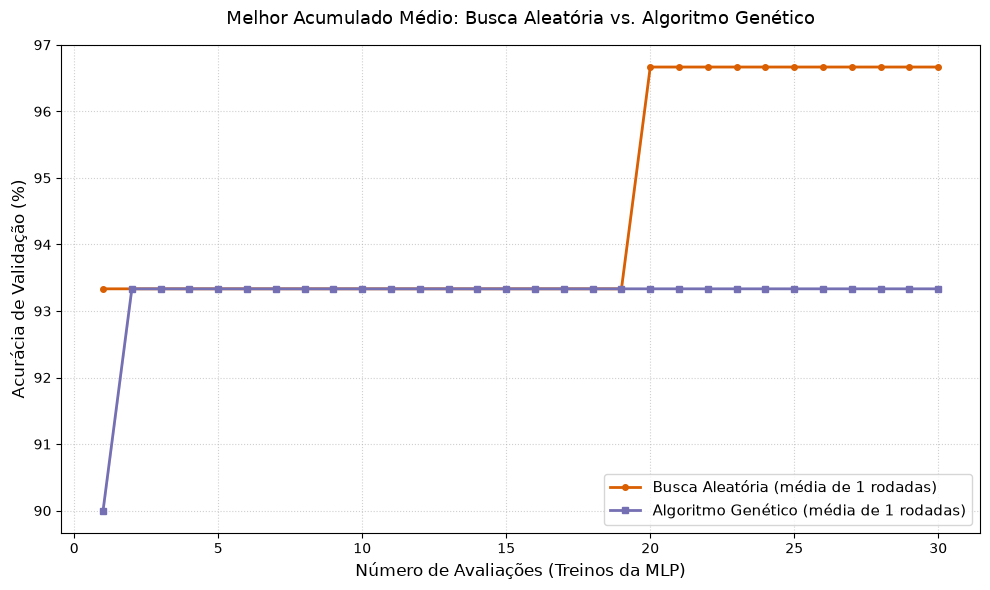

In [15]:
def plotar_media_rodadas(curvas_busca, curvas_ga, salvar="grafico_media_rodadas.png"):
    plt.figure(figsize=(10, 6))
    for curvas, nome, cor, marcador in [
        (curvas_busca, "Busca Aleatória", "#d95f02", "o"),
        (curvas_ga, "Algoritmo Genético", "#7570b3", "s"),
    ]:
        a = np.array(curvas) * 100
        media, desvio = a.mean(axis=0), a.std(axis=0)
        x = np.arange(1, a.shape[1] + 1)
        plt.plot(x, media, color=cor, marker=marcador, markersize=4, linewidth=2,
                 label=f"{nome} (média de {a.shape[0]} rodadas)")
        plt.fill_between(x, media - desvio, np.minimum(media + desvio, 100),
                         color=cor, alpha=0.15)
    plt.title("Melhor Acumulado Médio: Busca Aleatória vs. Algoritmo Genético",
              fontsize=13, pad=15)
    plt.xlabel("Número de Avaliações (Treinos da MLP)", fontsize=12)
    plt.ylabel("Acurácia de Validação (%)", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(fontsize=11, loc="lower right")
    plt.tight_layout()
    plt.show()

plotar_media_rodadas([r["curva_avaliacoes"] for r in res_busca],
                     [r["curva_avaliacoes"] for r in res_ga])

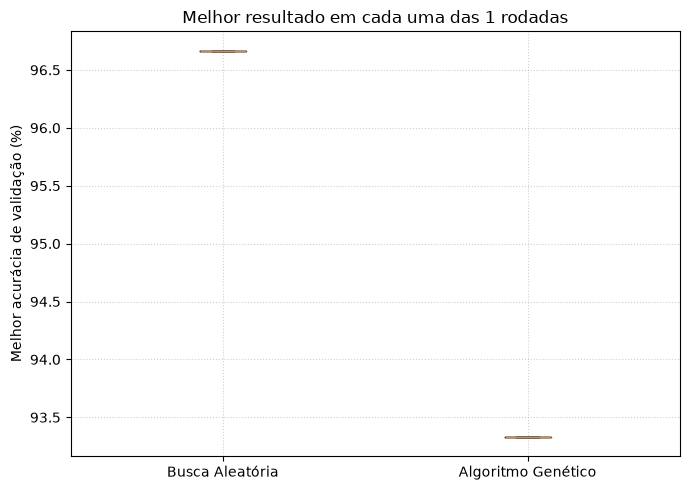

In [16]:
plt.figure(figsize=(7, 5))
plt.boxplot([np.array(fit_busca) * 100, np.array(fit_ga) * 100],
            tick_labels=["Busca Aleatória", "Algoritmo Genético"])
plt.ylabel("Melhor acurácia de validação (%)")
plt.title(f"Melhor resultado em cada uma das {NUM_RUNS} rodadas")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

-> Gráfico 'grafico_busca_aleatoria.png' salvo com sucesso!


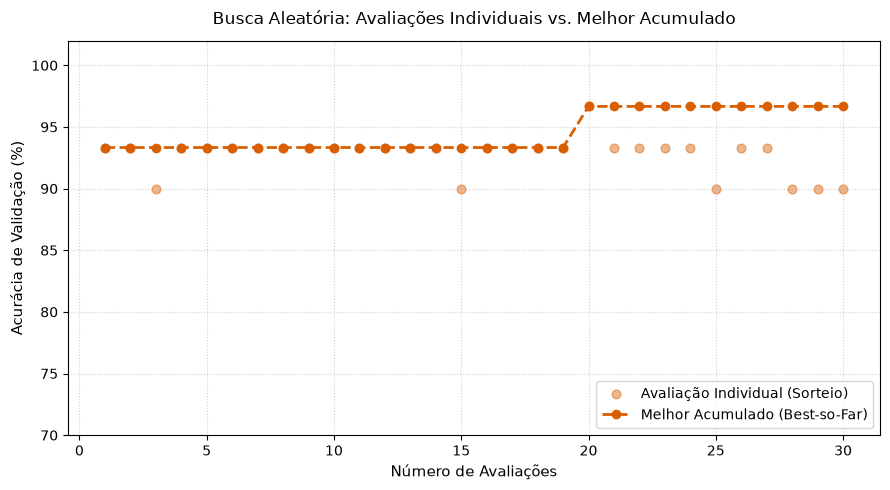

-> Gráfico 'grafico_algoritmo_genetico.png' salvo com sucesso!


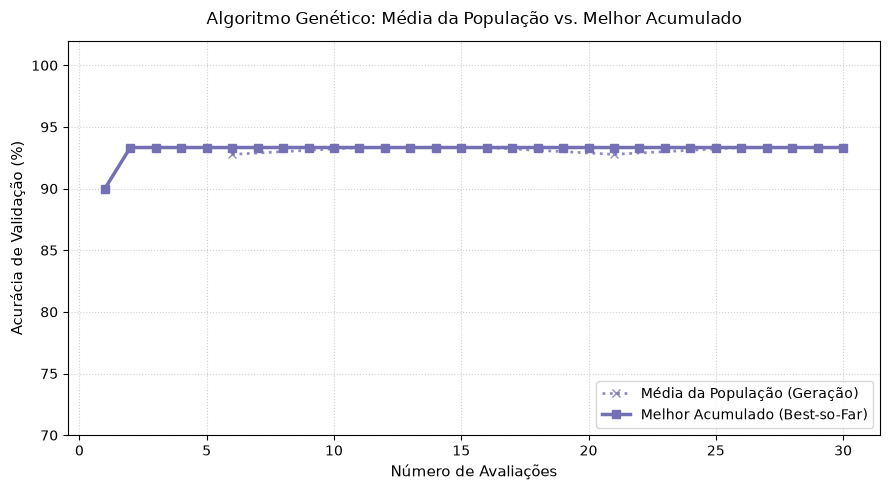

-> Gráfico 'grafico_comparativo.png' salvo com sucesso!


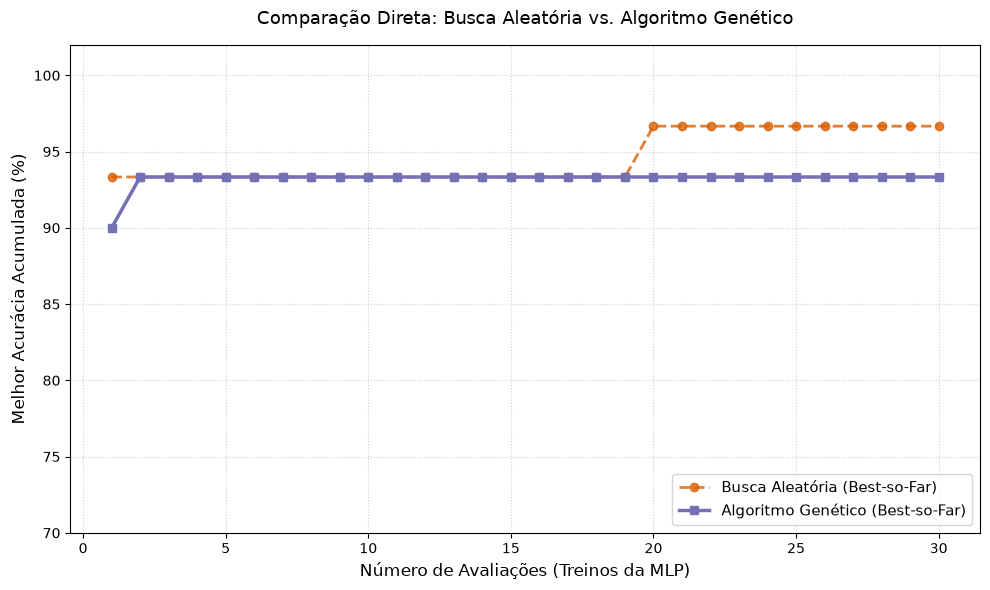

In [17]:
graficos.plotar_busca_aleatoria(res_busca[i_b]["curva_avaliacoes"],
                                res_busca[i_b]["fitness_avaliacoes"])
plt.show()

graficos.plotar_algoritmo_genetico(res_ga[i_g]["curva_avaliacoes"],
                                   res_ga[i_g]["historico"])
plt.show()

graficos.plotar_comparacao(res_busca[i_b]["curva_avaliacoes"],
                           res_ga[i_g]["curva_avaliacoes"])
plt.show()